# 02 · Milne–Witten similarity

**Goal:** measure how similar every pair of the 789 articles is, from their links, using the method of [Milne & Witten (2008)](https://www.coli.uni-saarland.de/courses/WebAsCorpus-12/papers/Milne-Witten-08.pdf). The result feeds the clustering in Step 3.

Milne & Witten compare two Wikipedia articles in two ways and combine them:

| Measure | Compares | Idea |
|---|---|---|
| **Out-link** | the pages each article links **to** | articles that link to the same (rare) pages are related |
| **In-link** | the pages that link **to** each article, from all of Wikipedia | articles that are linked from the same pages are related |
| **Milne–Witten** | both | the average of the two |

The measures are in `src/similarity.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import similarity
import wiki

pd.set_option("display.max_colwidth", 60)
SEED = "Hundred Years' War"

articles = pd.read_parquet(ROOT / "data" / "processed" / "articles.parquet")
links = pd.read_parquet(ROOT / "data" / "processed" / "links.parquet")
titles = articles["title"].tolist()
print(f"{len(titles)} articles | {len(links):,} links")

789 articles | 320,473 links


## 1. In-links from all of Wikipedia

The in-link measure needs, for each article, every article in Wikipedia that links to it (`get_backlinks`), and **W**, the number of articles in English Wikipedia (`get_article_count`). In-links from our network alone aren't enough: two-thirds of the network links to the seed, so the measure would mostly reflect popularity within the network. The first run takes about 45 minutes; after that, it loads from the cache.

In [2]:
W_info = wiki.get_article_count()
W = W_info["articles"]
print(f"W = {W:,} English Wikipedia articles (fetched {W_info['fetched']})")

backlinks = {t: wiki.get_backlinks(t) for t in tqdm(titles, desc="In-links")}
articles["n_links_in"] = articles["title"].map(lambda t: len(backlinks[t]))
articles[["title", "n_links_in"]].sort_values("n_links_in", ascending=False).head().reset_index(drop=True)

W = 7,248,637 English Wikipedia articles (fetched 2026-10-06)


In-links:   0%|          | 0/789 [00:00<?, ?it/s]

In-links:  43%|████▎     | 343/789 [00:00<00:00, 3409.20it/s]

In-links:  99%|█████████▉| 785/789 [00:00<00:00, 3782.45it/s]

In-links: 100%|██████████| 789/789 [00:00<00:00, 3714.87it/s]

,title,n_links_in
0,France,268122
1,World War II,232155
2,World War I,123377
3,French language,113238
4,Oxford University Press,44487


### How the in-link measure works

For two articles *a* and *b*, with **A** and **B** the sets of articles that link to them and **W** all articles in Wikipedia:

```
              log max(|A|,|B|) − log |A ∩ B|
distance  =  ───────────────────────────────          similarity = 1 − distance
              log W − log min(|A|,|B|)
```

- **|A ∩ B|** counts the articles that link to both (co-citation).
- **Numerator:** how far that overlap falls short of the more popular article. If everything that links to one also linked to the other, it would be 0.
- **Denominator:** how rare the less popular article is in all of Wikipedia. Sharing linkers means more when the articles are rare.
- **Logs** make the measure depend on ratios rather than differences ("twice as many" counts the same at any scale). Without them, W (7 million) would dwarf every other number and all pairs would look alike.

A worked example, *Battle of Crécy* and the seed:

In [3]:
a, b = "Battle of Crécy", SEED
A, B = set(backlinks[a]), set(backlinks[b])
shared = len(A & B)
numerator = np.log(max(len(A), len(B))) - np.log(shared)
denominator = np.log(W) - np.log(min(len(A), len(B)))
print(f"|A| = {len(A):,} articles link to {a}")
print(f"|B| = {len(B):,} articles link to {b}")
print(f"|A ∩ B| = {shared:,} link to both")
print(f"numerator   = log {max(len(A), len(B)):,} − log {shared:,} = {numerator:.2f}")
print(f"denominator = log {W:,} − log {min(len(A), len(B)):,} = {denominator:.2f}")
print(f"similarity  = 1 − {numerator:.2f} / {denominator:.2f} = {1 - numerator / denominator:.3f}")

|A| = 518 articles link to Battle of Crécy
|B| = 2,752 articles link to Hundred Years' War
|A ∩ B| = 266 link to both
numerator   = log 2,752 − log 266 = 2.34
denominator = log 7,248,637 − log 518 = 9.55
similarity  = 1 − 2.34 / 9.55 = 0.755


## 2. The out-link measure

Each article becomes a vector over the pages it links to, and two articles are compared by the **cosine** of the angle between their vectors (1 = the same links, 0 = none in common). Each link is weighted by how rare its target is, log(N / df), where df is how many of our N = 789 articles link to that page: a shared link to *England* says little, a shared link to *Siege of Meaux* says a lot. This is the same idea as TF-IDF in text search.

One simplification: the paper counts how many articles in *all of Wikipedia* link to each target; we count within our network, which avoids looking up ~110,000 link targets.

In [4]:
outlink = similarity.outlink_similarity(links, titles)
inlink = similarity.inlink_similarity(backlinks, W, titles)
print("Both measures: 789 × 789 tables of similarity between every pair of articles.")
print(f"Crécy vs the seed: out-link {outlink.at[a, b]:.3f} | in-link {inlink.at[a, b]:.3f}")

Both measures: 789 × 789 tables of similarity between every pair of articles.
Crécy vs the seed: out-link 0.179 | in-link 0.755


## 3. Combining the two

Milne & Witten average the two measures. But in our data they're on very different scales:

In [5]:
pairs = similarity.to_pairs({"outlink": outlink, "inlink": inlink})
pairs[["outlink", "inlink"]].describe(percentiles=[0.25, 0.5, 0.75]).loc[["25%", "50%", "75%", "max"]].round(4)

,outlink,inlink
25%,0.0001,0.3747
50%,0.0020,0.4869
75%,0.0080,0.6024
max,0.8863,0.9986


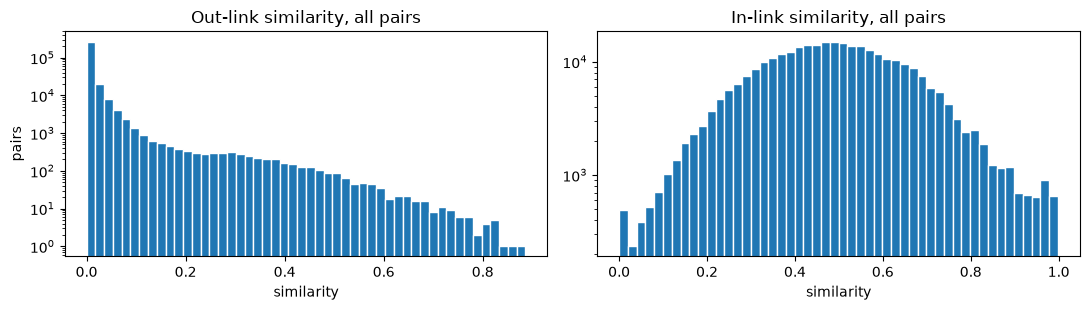

In [6]:
fig, (ax_out, ax_in) = plt.subplots(1, 2, figsize=(11, 3.2))
ax_out.hist(pairs["outlink"], bins=50, edgecolor="white")
ax_out.set(title="Out-link similarity, all pairs", xlabel="similarity", ylabel="pairs", yscale="log")
ax_in.hist(pairs["inlink"], bins=50, edgecolor="white")
ax_in.set(title="In-link similarity, all pairs", xlabel="similarity", yscale="log")
plt.tight_layout()

The typical pair scores about 0.002 on out-links and about 0.5 on in-links. Out-link similarity is near 0 for most pairs because two articles rarely share many of their hundreds of links. In-link similarity is high because the formula compares a pair against two random Wikipedia articles, and all our articles share at least the seed as a linker. A plain average would be decided almost entirely by the in-link half.

So we first convert each measure to **percentile ranks** (0 = the least similar pair, 1 = the most similar), then average them. Both halves then count equally.

In [7]:
milne_witten = similarity.rank_average(outlink, inlink)
measures = {"outlink": outlink, "inlink": inlink, "milne_witten": milne_witten}
pairs = similarity.to_pairs(measures)

# The 10 articles most similar to the seed, by each measure.
pd.DataFrame({m: measures[m][SEED].drop(SEED).nlargest(10).index for m in measures}, index=range(1, 11))

,outlink,inlink,milne_witten
1,"Hundred Years' War, 1369–1389",Edward III,Charles VII of France
2,Battle of Jargeau,Charles VII of France,Edward III
3,"Hundred Years' War, 1415–1453",Henry V of England,"Hundred Years' War, 1415–1453"
4,Battle of Beaugency (1429),Battle of Poitiers,"Hundred Years' War, 1337–1360"
5,"Hundred Years' War, 1337–1360",Battle of Crécy,Battle of Crécy
6,Battle of Meung-sur-Loire,Battle of Agincourt,Battle of Poitiers
7,Loire Campaign (1429),Black Death,"Hundred Years' War, 1369–1389"
8,Siege of Saint-Pierre-le-Moûtier,Wars of the Roses,Henry V of England
9,List of Hundred Years' War battles,Mongol invasion of Europe,Philip VI of France
10,Tournaisis campaign of 1340,"Hundred Years' War, 1415–1453",Battle of Agincourt


## 4. How the measures compare

### Agreement
**Spearman correlation** over all pairs: do two measures rank the pairs in the same order (1) or not at all (0)?

In [8]:
pairs[list(measures)].corr(method="spearman").round(2)

,outlink,inlink,milne_witten
outlink,1.00,0.42,0.83
inlink,0.42,1.00,0.84
milne_witten,0.83,0.84,1.00


### Examples
Each article's rank in similarity to the seed (1 = most similar, out of 788):

- *Battle of Crécy*, *Siege of La Charité*: part of the war
- *Kingdom of England*: broad context that many articles link to
- *Norfolk Record Office*: an archive, in the network because the seed cites a document held there

In [9]:
seed_similarity = pd.DataFrame({m: measures[m][SEED] for m in measures}).drop(SEED)
seed_rank = seed_similarity.rank(ascending=False).astype(int)
seed_rank.loc[["Battle of Crécy", "Siege of La Charité", "Kingdom of England", "Norfolk Record Office"]]

,outlink,inlink,milne_witten
Battle of Crécy,41,5,5
Siege of La Charité,62,319,220
Kingdom of England,288,129,133
Norfolk Record Office,598,785,755


### Articles linked from a template
Every article is in the network because the seed links to it. Templates (navboxes, sidebars) add 57% of the seed's links. The table compares each measure's average similarity to the seed when the seed's link was written in its text and when a template added it.

In [10]:
seed_links = links[links["source"] == SEED].drop_duplicates("target").set_index("target")
from_template = seed_links["from_template"].reindex(seed_similarity.index)
by_template = seed_similarity.groupby(from_template)
by_template.mean().assign(n_articles=by_template.size()).round(3)

,outlink,inlink,milne_witten,n_articles
from_template,,,,
False,0.049,0.563,0.754,336
True,0.073,0.630,0.841,452


## 5. Save

- `pairs.parquet`: one row per article pair (310,866 rows) with the three measures, for clustering.
- `seed_similarity.parquet`: each article's three scores and ranks relative to the seed.

In [11]:
for m, matrix in measures.items():
    values = matrix.to_numpy()
    assert np.allclose(values, values.T), f"{m} is not symmetric"
    assert np.allclose(np.diag(values), 1), f"{m} diagonal"
    assert values.min() >= 0 and values.max() <= 1, f"{m} range"
    assert not np.isnan(values).any(), f"{m} has NaN"
print("All three: symmetric, 1 on the diagonal, values in [0, 1], no NaN.")

out = ROOT / "data" / "processed"
pairs.to_parquet(out / "pairs.parquet", index=False)
pairs.to_csv(out / "pairs.csv", index=False, encoding="utf-8-sig")
seed_table = seed_similarity.join(seed_rank.add_suffix("_rank")).rename_axis("title").reset_index()
seed_table.to_parquet(out / "seed_similarity.parquet", index=False)
seed_table.to_csv(out / "seed_similarity.csv", index=False, encoding="utf-8-sig")
print(f"saved pairs ({len(pairs):,} rows) and seed_similarity ({len(seed_table)} rows)")

All three: symmetric, 1 on the diagonal, values in [0, 1], no NaN.


saved pairs (310,866 rows) and seed_similarity (788 rows)


## Findings

- **In-links find the war's core.** The in-link measure's top 10 for the seed are its kings, battles and consequences: *Edward III*, *Charles VII*, *Henry V*, *Poitiers*, *Crécy*, *Agincourt*, *Black Death*. In the worked example, 266 of the 518 articles that link to *Crécy* also link to the war.
- **Out-links find groups that share links.** The out-link measure's top 10 are the war's phases and the battles of the 1429 Loire campaign: articles listed together in the same navbox, so their link lists overlap.
- **The two halves capture different things** (Spearman 0.42), which is the point of combining them.
- **The rank average balances them:** Milne–Witten correlates about equally with both (0.83 and 0.84), and its top 10 mixes the war's leaders, phases and main battles.
- **Broad context and citation noise rank low:** *Kingdom of England* is 133rd and *Norfolk Record Office* 755th of 788.